# Una inversión ERT topográfica con control sintético conocido

**Nivel 3 — Experimento con el solver**  
**Prerrequisitos:** geometría Wenner, resistividad logarítmica, regularización y validación retenida; 60–90 min incluyendo el cálculo.

## Objetivos

¿Cuánto cambia el campo de potencial por un conductor lateralmente acotado? ¿La inversión 2D con topografía predice mediciones que no ajustó? ¿Cuánto varían el modelo y los errores retenidos al cambiar la malla o los errores supuestos?

## Preparación

Instala los pins exactos del notebook con `pip install numpy==2.2.6 matplotlib==3.10.8` y luego el motor aislado y fijado: `./scripts/setup.ps1 -Notebooks` y `./scripts/setup.ps1 -Ert` (Windows), o `scripts/setup.sh --notebooks` y `scripts/setup.sh --ert`. pyGIMLi requiere NumPy 2.5.3; queda aislado del NumPy 2.2.6 del entorno principal.

## Datos

El recibo versionado y verificado por SHA-256 fue generado por el script determinista. Cambia `RUN_SOLVER=True` en la celda experimental para repetir el cálculo con el entorno aislado `.venv-ert`. El script genera el perfil Wenner de 28 electrodos y cuatro separaciones. Los electrodos siguen una superficie curva; pyGIMLi calcula las respuestas para un fondo de 100 Ω m con un cuerpo finito de 25 Ω m. Se aplica una perturbación log-normal de 1% con semilla fija. Son observaciones simuladas con verdad explícita, nunca los datos restringidos de Slagdump.

## Método

Las resistencias sintéticas provienen de una solución de elementos finitos 2D de la ecuación de conductividad DC, con elevaciones reales de electrodos y un cuerpo conductor finito. La inversión usa el administrador ERT de pyGIMLi, factores geométricos numéricos con topografía, un modelo de resistividad logarítmica y los parámetros fijados del repositorio. La partición principal retiene cada quinta medición dentro de cada separación AB; el segundo ajuste retiene los cuadrupolos cuyo punto medio AB cae en el 40–60% central del perfil.

El objetivo de entrenamiento combina desajuste ponderado y regularización de suavidad. Los pesos usan el error supuesto documentado de 3% en resistencia; no se presenta como calibración instrumental. El experimento repite el ajuste con una malla de parámetros alternativa y con errores supuestos duplicados. Son controles de sensibilidad; no seleccionan un modelo mejor. Revisa la implementación y el criterio de parada condicional en `data-pipeline/ert.py`.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path
ledger=json.loads((root/"data/source-ledger.json").read_text(encoding="utf-8")); print("ledger mentions Slagdump:","slagdump" in json.dumps(ledger).lower()); raw=list((root/"data").rglob("*.ohm")); print("local .ohm files:",raw,"; inversion from field arrays possible:",bool(raw))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

paraDX [0.3, 0.45] dimensionless; maximum cell size [10.0, 15.0] m; alternate/default ratios 1.5 1.5


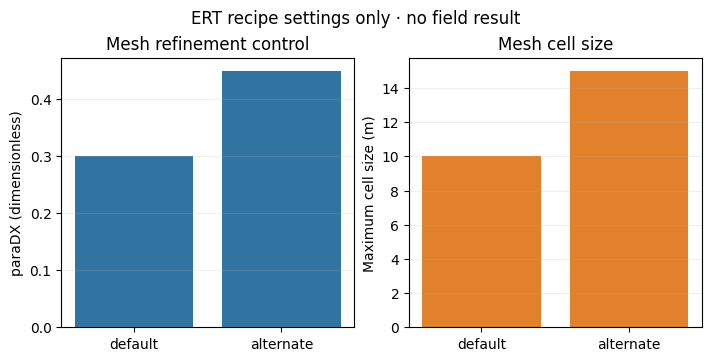

In [2]:
# Read default and alternate mesh parameters from the source AST; no mesh or field model is generated.
import ast
import numpy as np
import matplotlib.pyplot as plt
tree=ast.parse((root/"data-pipeline/ert.py").read_text(encoding="utf-8")); assigns={n.targets[0].id:n.value for n in tree.body if isinstance(n,ast.Assign) and isinstance(n.targets[0],ast.Name)}
default=ast.literal_eval(assigns["INVERSE_OPTIONS"]); alt_node=assigns["ALTERNATE_MESH_OPTIONS"]; overrides={k:ast.literal_eval(v) for k,v in zip([k.value for k in alt_node.keys if k is not None],[v for v in alt_node.values if not isinstance(v,ast.Name)])}; alternate={**default,**overrides}
labels=["default","alternate"]; dx=[default["paraDX"],alternate["paraDX"]]; cell=[default["paraMaxCellSize"],alternate["paraMaxCellSize"]]; print("paraDX",dx,"dimensionless; maximum cell size",cell,"m; alternate/default ratios",cell[1]/cell[0],dx[1]/dx[0])
fig,ax=plt.subplots(1,2,figsize=(7,3.5),constrained_layout=True); x=np.arange(2); ax[0].bar(x,dx,color="#3274a1"); ax[0].set(xticks=x,xticklabels=labels,ylabel="paraDX (dimensionless)",title="Mesh refinement control"); ax[1].bar(x,cell,color="#e1812c"); ax[1].set(xticks=x,xticklabels=labels,ylabel="Maximum cell size (m)",title="Mesh cell size"); [a.grid(axis="y",alpha=.2) for a in ax]; fig.suptitle("ERT recipe settings only · no field result"); plt.show()

### Experimento controlado de QC y geometría

Construye en memoria un sondeo Wenner `.ohm` **sintético** con elevaciones conocidas, respuesta nominal de semiespacio plano, dispersión con semilla fija y un valor atípico. Ejecuta el parser del repositorio, QC que solo marca, factores geométricos y validación predefinida. El factor ignora deliberadamente la elevación: compara la resistividad aparente diagnóstica con el relieve y explica por qué esto **no** es corrección topográfica ni inversión. No se infieren datos de terreno ni geología.

Las entradas y salidas son sintéticas; la marca conserva la medición y el factor plano es solo diagnóstico.

synthetic: 16 electrodes; 30 quadrupoles; relief=0.639 m
flagged zero-based rows=[5]; injected=5; all 30 measurements retained
predeclared split train=25 held=5; median apparent rho=99.07 ohm m; nominal rho=100 ohm m


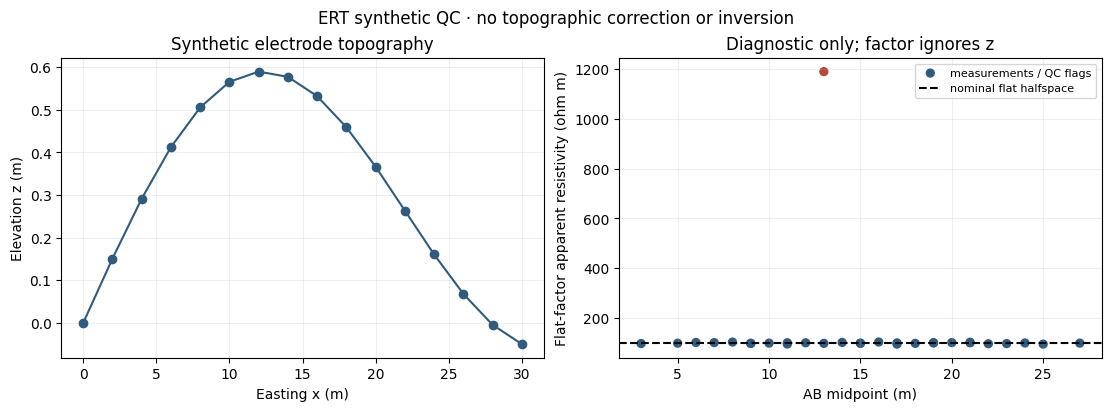

In [3]:
# Execute the documented experiment with the repository evidence.
import sys
sys.path.insert(0,str(root/"data-pipeline"))
import ert, numpy as np, matplotlib.pyplot as plt
ne=16; x=np.arange(ne,dtype=float)*2.; z=.45*np.sin(x/7.)+.012*x; rows=[]
for d in (1,2,3):
 for a in range(ne-3*d): rows.append((a+1,a+1+3*d,a+1+d,a+1+2*d))
def source(res):
 lines=["# Synthetic teaching fixture; not field data","# A Wenner array with 2m was applied.",f"{ne}# Number of sensors","#x z"]+[f"{xx:.6f} {zz:.6f}" for xx,zz in zip(x,z)]+[f"{len(rows)}# Number of data","#a b m n R"]+[f"{a} {b} {m} {n} {v:.12g}" for (a,b,m,n),v in zip(rows,res)]
 return ("\n".join(lines)+"\n").encode()
base=ert.parse_ohm_bytes(source(np.ones(len(rows)))); k=ert.flat_halfspace_factors(base); rng=np.random.default_rng(20261027); r=100./k*np.exp(rng.normal(0,.025,len(rows))); outlier=min(5,len(r)-1); r[outlier]*=12
s=ert.parse_ohm_bytes(source(r)); report=ert.qc(s); train,held=ert.holdout_indices(s); app=ert.flat_halfspace_factors(s)*s.resistance_ohm
print(f"synthetic: {report['sensor_count']} electrodes; {report['measurement_count']} quadrupoles; relief={report['topographic_relief_m']:.3f} m")
print(f"flagged zero-based rows={report['flagged_rows']}; injected={outlier}; all {len(r)} measurements retained")
print(f"predeclared split train={len(train)} held={len(held)}; median apparent rho={np.median(app):.2f} ohm m; nominal rho=100 ohm m")
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True); ax[0].plot(x,z,"o-",color="#315b7d"); ax[0].set(xlabel="Easting x (m)",ylabel="Elevation z (m)",title="Synthetic electrode topography"); ax[0].grid(alpha=.2)
mid=(x[s.abmn[:,0]]+x[s.abmn[:,1]])/2; flagged=np.isin(np.arange(len(app)),report["flagged_rows"]); ax[1].scatter(mid,app,c=np.where(flagged,"#b34a36","#315b7d"),s=32,label="measurements / QC flags"); ax[1].axhline(100,color="black",ls="--",label="nominal flat halfspace"); ax[1].set(xlabel="AB midpoint (m)",ylabel="Flat-factor apparent resistivity (ohm m)",title="Diagnostic only; factor ignores z"); ax[1].grid(alpha=.2); ax[1].legend(fontsize=8); fig.suptitle("ERT synthetic QC · no topographic correction or inversion"); plt.show()

### Experiment — run the forward and inverse solvers

In [4]:
# The committed receipt keeps normal notebook execution fast and bit-reproducible.
# Set RUN_SOLVER=True to regenerate the physical forward/inverse experiment (~1–2 minutes).
import hashlib, json, os, subprocess, tempfile
from pathlib import Path
source_root=Path(os.environ.get("CAOS_SOURCE_ROOT", root)).resolve()
receipt_path=root/"docs/design/features/m07-slagdump-ert/synthetic-control.json"
expected_receipt_sha256="b278bb3a06461dd537f85224348eac2e2b918cac916b4f2f3f55fa4528d4bb9d"
RUN_SOLVER=False
if RUN_SOLVER:
    ert_python=source_root/".venv-ert"/"Scripts"/"python.exe"
    if not ert_python.is_file(): ert_python=source_root/".venv-ert"/"bin"/"python"
    if not ert_python.is_file(): raise RuntimeError("M07 engine missing; run scripts/setup.ps1 -Ert or scripts/setup.sh --ert")
    with tempfile.TemporaryDirectory(prefix="caos-ert-notebook-") as work:
        output=Path(work)/"receipt.json"
        run=subprocess.run([str(ert_python),str(source_root/"data-pipeline"/"ert_synthetic_experiment.py"),"--output",str(output)],
                           cwd=source_root,capture_output=True,text=True,timeout=600)
        if run.returncode: raise RuntimeError("pyGIMLi experiment failed\n"+run.stdout+"\n"+run.stderr[-5000:])
        payload=output.read_bytes()
else:
    payload=receipt_path.read_bytes()
    sidecar=receipt_path.with_suffix(receipt_path.suffix+".sha256").read_text(encoding="ascii").strip()
    actual=hashlib.sha256(payload).hexdigest()
    if actual != expected_receipt_sha256 or sidecar != actual:
        raise RuntimeError(f"M07 synthetic receipt checksum mismatch: {actual}")
experiment=json.loads(payload)
if experiment["source_id"] != "original-synthetic-ert-control" or experiment["experiment"]["is_field_data"]:
    raise RuntimeError("refusing to display a receipt that is not explicitly synthetic")
print("engine:",experiment["engine"])
print("synthetic setup:",experiment["experiment"]["geometry"]["forward_model"])
print("inverse verdict:",experiment["inverse_status"],experiment.get("inverse_reason",""))
print("interleaved held-out log-RMSE:",round(experiment["inverse"]["heldout_log_r_rmse"],4))
print("spatial-blocked held-out log-RMSE:",round(experiment["blocked_validation"]["heldout_log_r_rmse"],4))


engine: {'pygimli_distribution': '1.6.1', 'pgcore_distribution': '1.6.0', 'numpy': '2.5.3', 'scipy': '1.17.1', 'options': {'lam': 10.0, 'paraDX': 0.3, 'paraMaxCellSize': 10.0, 'paraDepth': 20.0, 'quality': 33.6, 'maxIter': 12}}
synthetic setup: {'background_ohm_m': 100.0, 'body_ohm_m': 25.0, 'body_x_m': [21.0, 35.0], 'body_z_m': [-20.0, -5.0], 'forward_mesh_cells': 935, 'noise': 'seeded multiplicative log-normal, sigma=0.01', 'seed': 20261027}
inverse verdict: passed 
interleaved held-out log-RMSE: 0.0313
spatial-blocked held-out log-RMSE: 0.0656


### Compare truth, recovered model, coverage and residuals

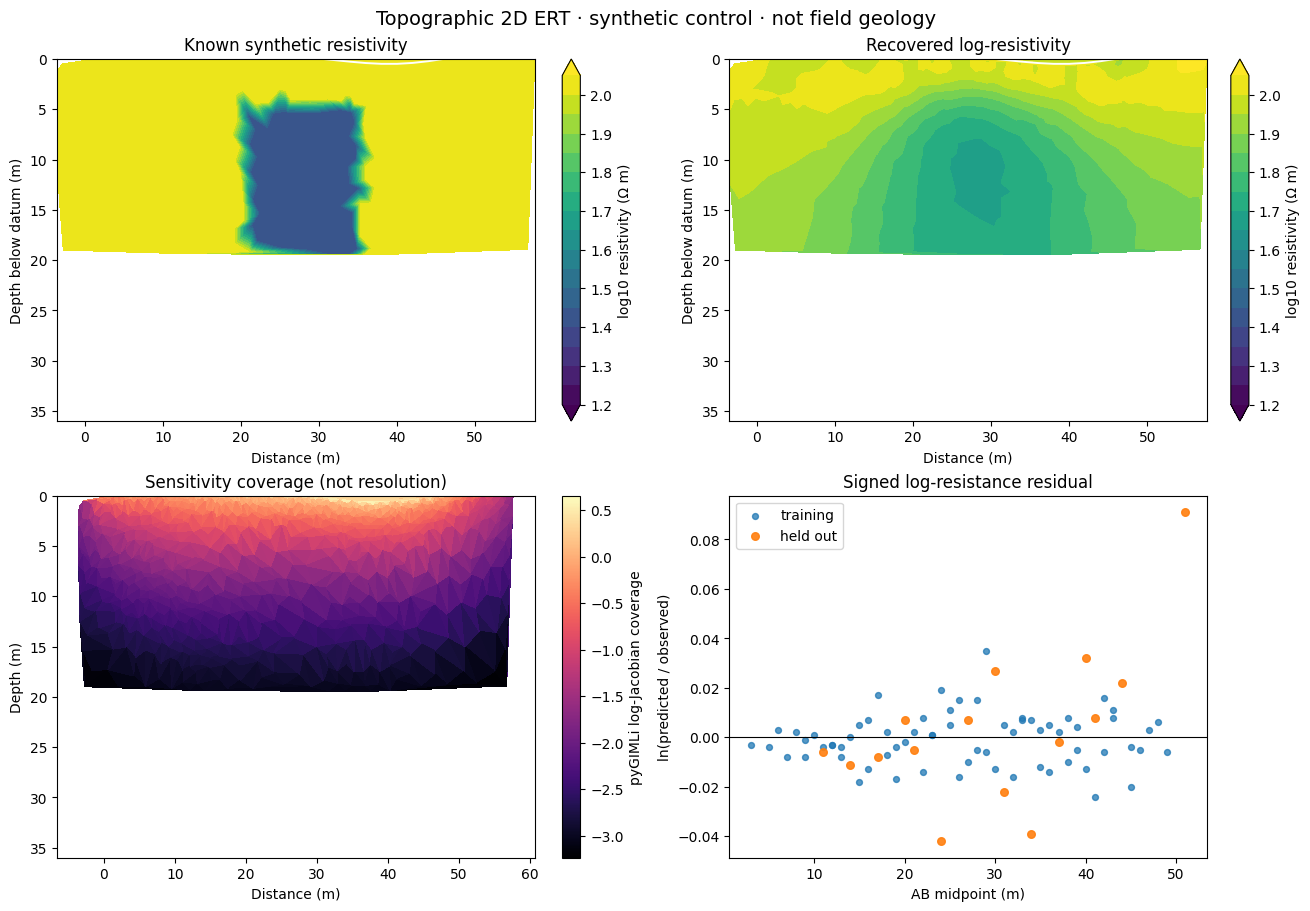

status: passed ; model cells: 835 ; cellwise log10 truth RMSE: 0.1208
held-out improvement vs homogeneous: 0.657 ; spatial-block improvement: 0.558
mesh perturbation held-out RMSE: 0.0315 ; doubled-error RMSE: 0.0288


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation
inv=experiment.get("inverse")
if inv is None: raise RuntimeError("inverse did not produce a model: "+experiment.get("inverse_reason","unknown reason"))
coords=np.asarray(inv["model_cell_center_xz_m"]); depth=-coords[:,1]
tri=Triangulation(coords[:,0],depth)
truth=np.asarray(experiment["synthetic_truth_comparison"]["truth_resistivity_ohm_m_at_parameter_cell_centers"])
model=np.asarray(inv["model_resistivity_ohm_m"])
coverage=np.round(np.asarray(inv["coverage_log10_sensitivity_per_cell"]),2)
survey=experiment["qc"]
observed=np.asarray(inv["observed_r_ohm"]); predicted=np.asarray(inv["predicted_r_ohm"])
train=np.asarray(experiment["split"]["training_rows"],dtype=int); held=np.asarray(experiment["split"]["heldout_rows"],dtype=int)
# Recover AB midpoints from the report's ordered observed vectors and source geometry.
xel=np.asarray(experiment["experiment"]["geometry"]["electrode_x_m"])
# Store split membership against measurements in the deterministic source order.
spans=[]
for spacing in (1,2,3,4):
    for a in range(len(xel)-3*spacing): spans.append((a,a+3*spacing))
midpoints=np.asarray([(xel[a]+xel[b])/2 for a,b in spans])
fig,ax=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
for axis,values,title in ((ax[0,0],truth,"Known synthetic resistivity"),(ax[0,1],model,"Recovered log-resistivity")):
    image=axis.tricontourf(tri,np.round(np.log10(values),2),levels=np.linspace(1.2,2.05,18),cmap="viridis",extend="both")
    fig.colorbar(image,ax=axis,label="log10 resistivity (Ω m)")
    axis.plot(experiment["experiment"]["geometry"]["electrode_x_m"],-np.asarray(experiment["experiment"]["geometry"]["electrode_z_m"]),color="white",lw=1.4)
    axis.set(title=title,xlabel="Distance (m)",ylabel="Depth below datum (m)",ylim=(36,0))
image=ax[1,0].tripcolor(tri,coverage,shading="flat",cmap="magma")
fig.colorbar(image,ax=ax[1,0],label="pyGIMLi log-Jacobian coverage")
ax[1,0].set(title="Sensitivity coverage (not resolution)",xlabel="Distance (m)",ylabel="Depth (m)",ylim=(36,0))
ax[1,1].scatter(midpoints[train],np.round(np.log(predicted[train]/observed[train]),3),s=18,label="training",alpha=.75)
ax[1,1].scatter(midpoints[held],np.round(np.log(predicted[held]/observed[held]),3),s=30,label="held out",alpha=.9)
ax[1,1].axhline(0,color="black",lw=.8); ax[1,1].set(title="Signed log-resistance residual",xlabel="AB midpoint (m)",ylabel="ln(predicted / observed)"); ax[1,1].legend()
fig.suptitle("Topographic 2D ERT · synthetic control · not field geology",fontsize=14)
plt.show()
print("status:",experiment["inverse_status"],"; model cells:",inv["mesh_cells"],"; cellwise log10 truth RMSE:",round(experiment["synthetic_truth_comparison"]["log10_rmse_over_parameter_cells"],4))
print("held-out improvement vs homogeneous:",round(inv["heldout_improvement_vs_homogeneous"],3),"; spatial-block improvement:",round(experiment["blocked_validation"]["improvement_vs_homogeneous"],3))
print("mesh perturbation held-out RMSE:",round(experiment["sensitivity"]["alternate_mesh"]["heldout_log_r_rmse"],4),"; doubled-error RMSE:",round(experiment["sensitivity"]["doubled_assumed_error"]["heldout_log_r_rmse"],4))


## Resultados

Un veredicto inverso aprobado significa que pasaron las reglas predictivas sintéticas predeclaradas en esta ejecución. No aprueba el caso de campo Slagdump, que es independiente. Compara las predicciones retenidas en las particiones intercalada y espacial con el baseline homogéneo de cada una; examina conjuntamente la estructura de residuos, resistividad recuperada y verdadera, y cobertura del Jacobiano. La cobertura es sensibilidad, no resolución. La malla es una parametrización suavizada y el error frente a la verdad sintética es una puntuación controlada, no una estimación de incertidumbre de campo.

El modelo 2D de línea, los errores supuestos, la malla finita, la regularización y el perfil único limitan la transferencia. La partición espacial puede compartir electrodos en sus bordes. Otra geometría, dimensionalidad o modelo de ruido requiere un experimento nuevo.

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)